In [17]:
import os

print("Model exists:",
      os.path.exists("models/unet_pascal_voc.pth"))

print("File size:",
      os.path.getsize("models/unet_pascal_voc.pth"),
      "bytes")

Model exists: True
File size: 7466069 bytes


In [16]:
import os

print(os.listdir("models"))

['unet_pascal_voc.pth']


In [15]:
os.makedirs("models", exist_ok=True)

torch.save(unet_model.state_dict(), "models/unet_pascal_voc.pth")

print("U-Net model saved to models/unet_pascal_voc.pth")

U-Net model saved to models/unet_pascal_voc.pth


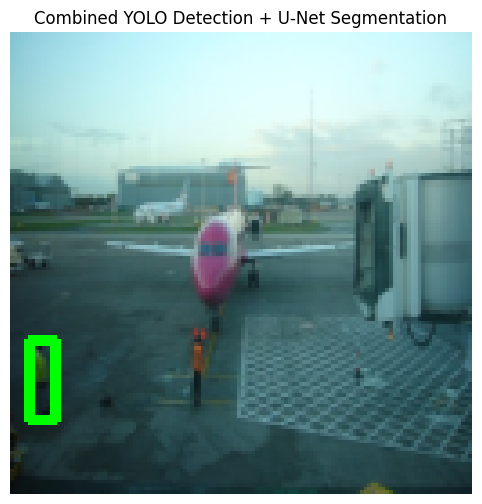

In [14]:
combined_image = sample_image_np.copy()

for box in results[0].boxes:
    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().astype(int)

    cropped_object = sample_image_np[y1:y2, x1:x2]

    if cropped_object.size == 0:
        continue

    resized_crop = cv2.resize(cropped_object, (IMG_SIZE, IMG_SIZE))
    crop_tensor = transforms.ToTensor()(resized_crop).unsqueeze(0).to(device)

    with torch.no_grad():
        seg_output = unet_model(crop_tensor)
        seg_mask = torch.argmax(seg_output, dim=1).squeeze().cpu().numpy()

    seg_mask_resized = cv2.resize(
        seg_mask.astype(np.uint8),
        (x2 - x1, y2 - y1),
        interpolation=cv2.INTER_NEAREST
    )

    overlay = combined_image[y1:y2, x1:x2].copy()
    overlay[seg_mask_resized > 0] = [255, 0, 0]

    combined_image[y1:y2, x1:x2] = cv2.addWeighted(
        combined_image[y1:y2, x1:x2],
        0.6,
        overlay,
        0.4,
        0
    )

    cv2.rectangle(combined_image, (x1, y1), (x2, y2), (0, 255, 0), 2)

plt.figure(figsize=(8, 6))
plt.title("Combined YOLO Detection + U-Net Segmentation")
plt.imshow(combined_image)
plt.axis("off")
plt.show()


0: 640x640 1 person, 41.5ms
Speed: 4.1ms preprocess, 41.5ms inference, 0.4ms postprocess per image at shape (1, 3, 640, 640)


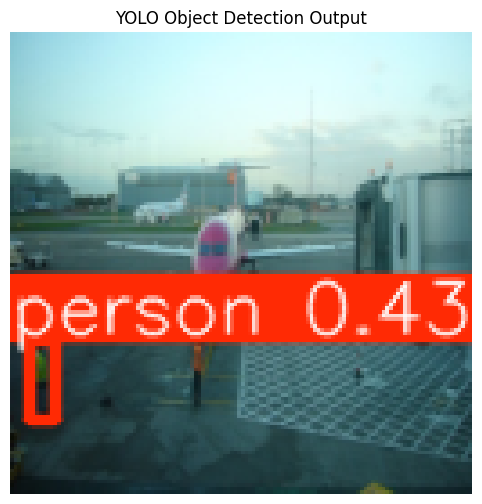

In [13]:
# Convert tensor image back to numpy format for YOLO
sample_image_np = (test_image.permute(1, 2, 0).numpy() * 255).astype(np.uint8)

# Make image memory contiguous for Ultralytics plotting
sample_image_np = np.ascontiguousarray(sample_image_np)

# Run YOLO detection
results = yolo_model(sample_image_np)

# Plot detections
annotated_image = results[0].plot()

plt.figure(figsize=(8, 6))
plt.title("YOLO Object Detection Output")
plt.imshow(annotated_image)
plt.axis("off")
plt.show()

In [11]:
yolo_model = YOLO("yolov8n.pt")
print("YOLO model loaded successfully.")

YOLO model loaded successfully.


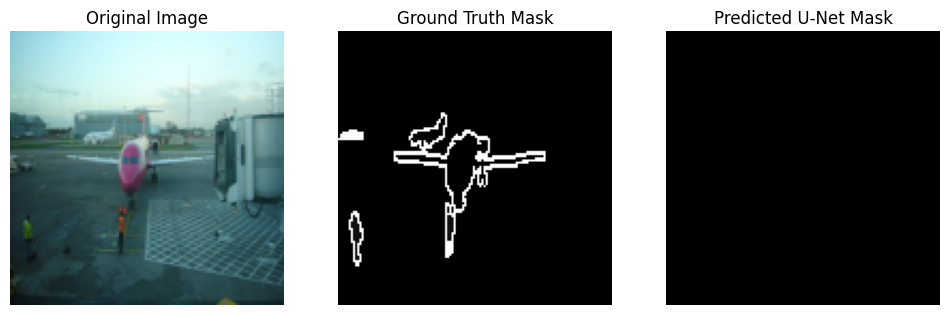

In [10]:
unet_model.eval()

with torch.no_grad():
    test_image, test_mask = voc_dataset[0]
    input_image = test_image.unsqueeze(0).to(device)

    prediction = unet_model(input_image)
    predicted_mask = torch.argmax(prediction, dim=1).squeeze().cpu().numpy()

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.title("Original Image")
plt.imshow(test_image.permute(1, 2, 0))
plt.axis("off")

plt.subplot(1, 3, 2)
plt.title("Ground Truth Mask")
plt.imshow(test_mask.squeeze(), cmap="gray")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.title("Predicted U-Net Mask")
plt.imshow(predicted_mask, cmap="gray")
plt.axis("off")

plt.show()

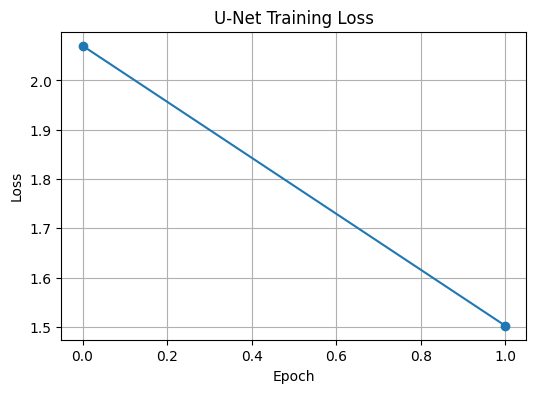

In [9]:
plt.figure(figsize=(6, 4))
plt.plot(loss_history, marker="o")
plt.title("U-Net Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

In [8]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(unet_model.parameters(), lr=0.001)

EPOCHS = 2

loss_history = []

for epoch in range(EPOCHS):
    unet_model.train()
    running_loss = 0.0

    for batch_idx, (images, masks) in enumerate(dataloader):
        images = images.to(device)
        masks = masks.squeeze(1).long().to(device)

        # Pascal VOC uses 255 as border/void label.
        masks[masks == 255] = 0

        outputs = unet_model(images)
        loss = criterion(outputs, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        if batch_idx >= 20:
            break

    avg_loss = running_loss / 21
    loss_history.append(avg_loss)
    print(f"Epoch [{epoch+1}/{EPOCHS}], Loss: {avg_loss:.4f}")

Epoch [1/2], Loss: 2.0704
Epoch [2/2], Loss: 1.5023


In [7]:
class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=21):
        super(UNet, self).__init__()

        def conv_block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, kernel_size=3, padding=1),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_c, out_c, kernel_size=3, padding=1),
                nn.ReLU(inplace=True)
            )

        self.encoder1 = conv_block(in_channels, 64)
        self.pool1 = nn.MaxPool2d(2)

        self.encoder2 = conv_block(64, 128)
        self.pool2 = nn.MaxPool2d(2)

        self.bottleneck = conv_block(128, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.decoder2 = conv_block(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.decoder1 = conv_block(128, 64)

        self.output_layer = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.encoder1(x)
        p1 = self.pool1(e1)

        e2 = self.encoder2(p1)
        p2 = self.pool2(e2)

        b = self.bottleneck(p2)

        u2 = self.up2(b)
        d2 = self.decoder2(torch.cat([u2, e2], dim=1))

        u1 = self.up1(d2)
        d1 = self.decoder1(torch.cat([u1, e1], dim=1))

        return self.output_layer(d1)


unet_model = UNet().to(device)
print(unet_model)

UNet(
  (encoder1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (encoder2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (bottleneck): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (up2): ConvTranspose2d(256, 128, kernel_size=(2, 2), stride=(2, 2))
  (decoder2): Sequential(
    (0): C

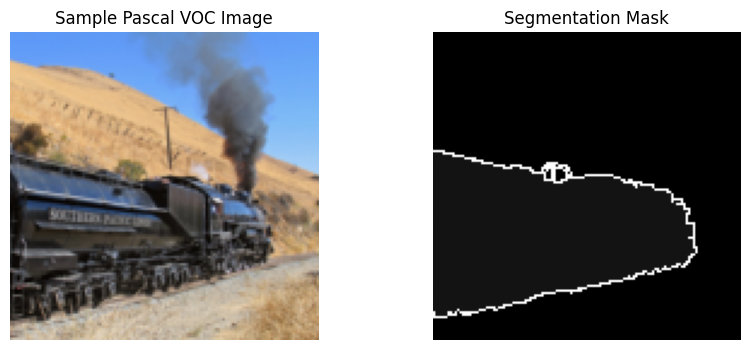

In [6]:
images, masks = next(iter(dataloader))

sample_image = images[0].permute(1, 2, 0).numpy()
sample_mask = masks[0].squeeze().numpy()

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.title("Sample Pascal VOC Image")
plt.imshow(sample_image)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.title("Segmentation Mask")
plt.imshow(sample_mask, cmap="gray")
plt.axis("off")

plt.show()

In [5]:
voc_dataset = datasets.VOCSegmentation(
    root="data",
    year="2012",
    image_set="train",
    download=True,
    transform=image_transform,
    target_transform=mask_transform
)

dataloader = DataLoader(
    voc_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

print("Pascal VOC dataset loaded.")
print("Number of training samples:", len(voc_dataset))

100%|██████████| 2.00G/2.00G [02:05<00:00, 15.9MB/s] 


Pascal VOC dataset loaded.
Number of training samples: 1464


In [4]:
IMG_SIZE = 128
BATCH_SIZE = 4

image_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

mask_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=Image.NEAREST),
    transforms.PILToTensor()
])

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [1]:
# CST 544 Week 4 Assignment
# Object Detection and Segmentation using YOLO and U-Net

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

import torchvision
from torchvision import datasets, transforms

from ultralytics import YOLO

print("Environment setup complete.")
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/Users/boatismbair/Library/Application Support/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Environment setup complete.
PyTorch version: 2.12.0
Torchvision version: 0.27.0


# CST 544 Week 4 Assignment  
## Object Detection and Segmentation Model Using YOLO and U-Net

This project builds an integrated computer vision pipeline using YOLO for object detection and U-Net for semantic segmentation. The Pascal VOC dataset is used to load images and segmentation masks. YOLO identifies objects through bounding boxes, while U-Net performs pixel-level segmentation to outline object regions.

In [2]:
import cv2

print(cv2.__version__)

4.13.0
